# Basic trying things (skip)

In [ ]:
import kdsource.api as kds
import numpy as np

In [ ]:
help(kds.write_mcpl)

In [ ]:
file_path = "my_data.mcpl.gz"

empty_10 = np.zeros(10)
full_10 = np.ones(10)
kds.write_mcpl(filename=file_path, ekin=full_10, x=empty_10, y=empty_10, z=empty_10, ux=full_10, uy=empty_10, uz=empty_10, time=empty_10, weight=full_10, pdgcode=2112)

In [ ]:
import mcpl
import pandas as pd

myfile=mcpl.MCPLFile(file_path,blocklength=2)
datas = []
for i,p in enumerate(myfile.particle_blocks):
    print("block no.", i)
    data = pd.DataFrame({
        'Kf': p.pdgcode,  # Particle PDG code
        'x': p.x,  # x-position
        'y': p.y,  # y-position
        'z': p.z,  # z-position
        'Vx': p.ux,  # Velocity in x-direction
        'Vy': p.uy,  # Velocity in y-direction
        'Vz': p.uz,  # Velocity in z-direction
        'e': p.ekin,  # Kinetic energy
        'Wt': p.weight  # Weight of the particle
    })
    datas.append(data)
data = pd.concat(datas, ignore_index=True)
data

In [ ]:
data.dtypes

In [ ]:
myfile=mcpl.MCPLFile("./examples/uniform/output.mcpl.gz",blocklength=100)
datas = []
for i,p in enumerate(myfile.particle_blocks):
    if i==1: break
    data = pd.DataFrame({
        'Kf': p.pdgcode,  # Particle PDG code
        'x': p.x,  # x-position
        'y': p.y,  # y-position
        'z': p.z,  # z-position
        'Vx': p.ux,  # Velocity in x-direction
        'Vy': p.uy,  # Velocity in y-direction
        'Vz': p.uz,  # Velocity in z-direction
        'e': p.ekin,  # Kinetic energy
        'Wt': p.weight  # Weight of the particle
    })
    datas.append(data)
data = pd.concat(datas, ignore_index=True)
data

In [ ]:
kds.write_mcpl(filename=file_path, ekin=data["e"], x=data["x"], y=data["y"], z=data["z"],
                ux=data["Vx"], uy=data["Vy"], uz=data["Vz"], time=np.zeros_like(data["Kf"]), weight=data["Wt"], pdgcode=data["Kf"])

In [ ]:
import kdsource.api as kds  # Importing the KDSource Python API

In [ ]:
kds.Geometry?

In [ ]:
kds.Metric?

In [ ]:
kds.geom._metrics

In [ ]:
my_energy = kds.geom.Energy()
#my_lethargy = kds.geom.Lethargy()

In [ ]:
type(my_energy)

In [ ]:
for k,v in my_energy.__dict__.items():
    print(k, str(v))

In [ ]:
# for k,v in my_lethargy.__dict__.items():
#     print(k, str(v))

In [ ]:
my_position = kds.geom.Vol()
my_time = kds.geom.Time()
my_directions = kds.geom.Isotrop()

In [ ]:
my_geometry = kds.Geometry([
    my_energy, my_time, my_position, my_directions
])

In [ ]:
for k,v in my_geometry.__dict__.items():
    print(k, str(v))

In [ ]:
kds.KDSource?

In [ ]:
import kdsource

In [ ]:
kdsource?

In [ ]:
kds.kde.bw_methods

In [ ]:
# Step 1: Load your original MCPL particle track list file
my_input_file_path = "./examples/uniform/output.mcpl.gz"

my_input_plist = kds.PList(filename=my_input_file_path,
                           readformat="mcpl",
                           pt="n",
                           trasl=None,
                           rot=None,
                           switch_x2z=False,
                           set_params=True)


In [ ]:
vars(my_input_plist)

In [ ]:
my_source.fitted

In [ ]:
my_source = kds.KDSource(
    plist=my_input_plist, geom=my_geometry, bw="mlcv", J=1.0, kernel="gaussian"
)

In [ ]:
my_source.fitted

In [ ]:
[attr for attr in dir(my_source) if attr[0:2]!="__"]

In [ ]:
vars(my_source.plist)

In [ ]:
my_source.fitted, my_source.bw_method

In [ ]:
my_source.fit(N=10000)

In [ ]:
vars(my_source.geom)

In [ ]:
my_source.kde.fit?

In [ ]:
my_source.fitted

In [ ]:
import numpy as np
my_source.plot_t(np.array([-1,0,1]))

In [ ]:
my_source.kde.data

In [ ]:
my_source.plot_E(grid_E=np.array([0,1e-8,2e-8,3e-8]))

In [ ]:
my_source.plot_integr(var="x", grid=np.arange(-5,5,0.2));

In [ ]:
my_source.save()

In [ ]:
kds.resample_to_mcpl("_source.xml", "generated_from_source.mcpl.gz", nout=100)

In [ ]:
import mcpl
import pandas as pd

gen_file=mcpl.MCPLFile("generated_from_source.mcpl.gz")
datas = []
for i,p in enumerate(gen_file.particle_blocks):
    print("block no.", i)
    data = pd.DataFrame({
        'Kf': p.pdgcode,  # Particle PDG code
        'x': p.x,  # x-position
        'y': p.y,  # y-position
        'z': p.z,  # z-position
        'Vx': p.ux,  # Velocity in x-direction
        'Vy': p.uy,  # Velocity in y-direction
        'Vz': p.uz,  # Velocity in z-direction
        'e': p.ekin,  # Kinetic energy
        'Wt': p.weight  # Weight of the particle
    })
    datas.append(data)
data = pd.concat(datas, ignore_index=True)
data

In [ ]:
my_input_plist.N

In [ ]:
kdsource.plist.pt2pdg?

# methods
read_data, resample_df, resample_df_gen, generate_data, plot_data_row

## method definitions

In [1]:
import kdsource.api as kds
import mcpl
import pandas as pd
from pathlib import Path
import tempfile

def read_data(file_path, n=-1):
    """
    Read up to n particles from the mcpl file. n==-1 means read all.
    """
    blocklength = 10000
    gen_file = mcpl.MCPLFile(file_path, blocklength=blocklength)
    datas = []
    for i, p in enumerate(gen_file.particle_blocks):
        data = pd.DataFrame(
            {
                "Kf": p.pdgcode,  # Particle PDG code
                "x": p.x,  # x-position
                "y": p.y,  # y-position
                "z": p.z,  # z-position
                "Vx": p.ux,  # Velocity in x-direction
                "Vy": p.uy,  # Velocity in y-direction
                "Vz": p.uz,  # Velocity in z-direction
                "e": p.ekin,  # Kinetic energy
                "Wt": p.weight,  # Weight of the particle
            }
        )
        datas.append(data)
        if n != -1 and (i + 1) * blocklength >= n:
            break
    data = pd.concat(datas, ignore_index=True)
    if n != -1 and len(data) > n:
        data = data[:n]
    return data

def resample_df(
    source,
    dest,
    nout,
    rng=None,
    force=False,
    no_df=False,
    del_dest=False,
    del_source=False,
):
    """
    Generates data at `dest` and by default returns it as a pandas dataframe.
    - source: source model .xml file (which contains the original data path that is required for sampling)
    - dest: a file path with .mcpl.gz ending
    - nout: amount of particles generated
    - rng: rng parameter
    - force: whether `dest` file may be overwritten if it already exists
    - no_df: whether you do NOT want to receive a dataframe for some reason
    - del_dest: whether to delete file at `dest` in the end
    - del_source: whether or not to delete the source .xml file in the end

    Returns
    - pandas dataframe, or `dest`, or None
    """
    # print("Amount of particles to generate:", str(nout))
    kds.resample_to_mcpl(
        kds_sourcefile=source,
        destination_mcpl=dest,
        nout=nout,
        rng=rng,
        force=force,
    )
    # print("Data generated at", dest)
    if not no_df:
        data = read_data(dest)
    if del_dest:
        Path(dest).unlink()
    if del_source:
        Path(source).unlink()
    if not no_df:
        return data
    if not del_dest:
        return dest
    return None

def resample_df_gen(source, dest, nout, rng=None, del_dest=False, del_source=False):
    """
    A generator for dataframes via the resample method using an intermediate mcpl.gz file at `dest`. ATTENTION: Overwrites `dest` in each iteration!
    - source: source model .xml file (which contains the original data path that is required for sampling)
    - dest: a file path with .mcpl.gz ending
    - nout: amount of particles per dataframe
    - rng: If you specify it, it will be used for all the generated data. If None, uses new random rng for each iteration.
    - del_dest: whether or not to delete the most recent intermediate mcpl.gz file on the disk
    - del_source: whether or not to delete the source .xml file in the end (after the generator has stopped)
    """
    try:
        while True:
            yield resample_df(
                source=source,
                dest=dest,
                nout=nout,
                rng=rng,
                force=True,
                no_df=False,
                del_dest=del_dest,
                del_source=False,
            )
    finally:
        if del_source:
            Path(source).unlink()




def generate_data(
    inputFile,
    output_path=None,
    overwrite_output=False,
    n_gen=1_000,
    pt="n",
    n_fit=-1,
    kernel="gaussian",
    bw="silv",
    pCurrent=1.0,
    model_path=None,
    overwrite_model=False,
    generator=False,
):
    """
    Generates data similar to inputFile using kdsource, which uses KDE (Kernel Density Estimation) modeling.

    Parameters
    ---
    - inputFile: file path to input data; requires ending `.mcpl` or `.mcpl.gz`
    - output_path: file path for generated data (optional, see "Returns" section); file ending will be `.mcpl.gz`
    - overwrite_output: whether already existing file at output_path may be overwritten
    - n_gen: amount of particles to generate
    - pt: particle type ("n", "p", or "e") of generated particles and of input particles used for fitting the KDE model
    - n_fit: amount of input particles (with type `pt`) used for fitting of the source model (-1 means all)
    - kernel: kernel shape ("gaussian", "box", or "epa" (Epanechnikov))
    - bw: method for finding kernel bandwidth ("silv", "knn" or "mlcv")
    - pCurrent: total source particle current
    - model_path: where to save the model xml file (None makes it temporary)
    - overwrite_model: whether already existing file at model_path may be overwritten
    - generator: whether you want a generator for dataframes instead of one dataframe. `n_gen` will be the amount per yield.

    Returns
    ---
    - If output_path is specified: None. (The data will be saved to the file.)
    - If output_path is None: Pandas dataframe. Or, if `generator` is True: Generator of pandas dataframes.
    """

    inputFile = str(Path(inputFile).absolute())

    return_a_df = False
    output_is_temp = False
    model_is_temp = False

    if output_path is not None:
        output_path = Path(output_path).absolute().with_suffix(".mcpl.gz")
        if output_path.exists() and not overwrite_output:
            raise ValueError(
                "Output file already exists and overwriting is not allowed"
            )
        output_path = str(output_path)
    else:
        return_a_df = True
        output_path = str(Path(tempfile.gettempdir()) / "brightify_kdsource.mcpl.gz")
        output_is_temp = True

    if model_path is not None:
        model_path = Path(model_path).absolute().with_suffix(".xml")
        if model_path.exists() and not overwrite_model:
            raise ValueError("Model file already exists and overwriting is not allowed")
        model_path = str(model_path)
    else:
        model_path = str(Path(tempfile.gettempdir()) / "brightify_kdsource.xml")
        model_is_temp = True

    my_input_plist = kds.PList(
        filename=inputFile,
        readformat="mcpl",
        pt=pt,
        trasl=None,
        rot=None,
        switch_x2z=False,
        set_params=True,
    )
    # print(vars(my_input_plist))

    my_energy = kds.geom.Energy()
    my_time = kds.geom.Time()
    my_position = kds.geom.Vol()
    my_directions = kds.geom.Isotrop()
    my_geometry = kds.Geometry([my_energy, my_time, my_position, my_directions])
    # print(vars(my_geometry))

    my_source = kds.KDSource(
        plist=my_input_plist, geom=my_geometry, bw=bw, J=pCurrent, kernel=kernel
    )
    # print(vars(my_source))

    if n_fit == -1 or n_fit > my_input_plist.N:
        n_fit = my_input_plist.N
    # print("Amount of particles for fitting:", n_fit)

    my_source.fit(N=n_fit)

    model_path = str(Path(my_source.save(xmlfilename=model_path)).absolute())
    # if not model_is_temp:
    #     print("Source model saved to", model_path)
    # else:
    #     print("Temporary source model saved to", model_path)



    if not return_a_df:
        kds.resample_to_mcpl(
            kds_sourcefile=model_path,
            destination_mcpl=output_path,
            nout=n_gen,
            rng=None,
            force=True,
        )
        if model_is_temp:
            Path(model_path).unlink()
        return output_path
    else:
        if not generator:
            return resample_df(
                source=model_path,
                dest=output_path,
                nout=n_gen,
                rng=None,
                force=True,
                no_df=False,
                del_dest=output_is_temp,
                del_source=model_is_temp,
            )
        else:
            return resample_df_gen(
                source=model_path,
                dest=output_path,
                nout=n_gen,
                rng=None,
                del_dest=output_is_temp,
                del_source=model_is_temp,
            )

In [2]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

def plot_data_row(datas, rows=["x", "Vx", "e", "Wt"]):
    colors = list(mcolors.TABLEAU_COLORS.values())
    for j, row in enumerate(rows):
        color = colors[j]
        for i, data in enumerate(datas):
            plt.hist(data[row], density=True, bins=20, histtype="step", label=row+" "+str(i), color=color, linestyle=(0,(i%2+1,i*2+1)))
    plt.legend()
    plt.show()

## examples (skip)

In [ ]:
data1 = generate_data(inputFile=example_path, n_gen=100_000, n_fit=1_000_000, bw="silv")

In [ ]:
data2 = read_data(example_path, 100_000)

In [ ]:
gen = generate_data(
    inputFile=example_path,
    output_path=None,
    overwrite_output=False,
    n_gen=100,
    pt="n",
    n_fit=100_000,
    kernel="gaussian",
    bw="silv",
    pCurrent=1.0,
    model_path=None,
    overwrite_model=False,
    generator=True,
)

In [ ]:
data3=next(gen)

In [ ]:
gen.close()

In [ ]:
data3=next(gen)

In [ ]:
import numpy as np

In [ ]:
for d in [data1, data2, data3]:
    d["V_norm"] = np.sqrt((d.Vx*d.Vx + d.Vy*d.Vy + d.Vz+d.Vz))

In [ ]:
data1.describe()

In [ ]:
data2.describe()

In [ ]:
data3.describe()

In [ ]:
plot_data_row(datas=[data1, data2, data3], rows=["e", "x", "Vx"])

# Exercise 26.10. - 30.10.

## file paths and manual inspection

In [3]:
example_path_1 = "./examples/Brightify Fig 6/Fig6a/output.mcpl.gz"  # const: ekin=2.5e-08, weight=1; almost const: z=0.06; n = 20_139_128
example_path_2 = "./examples/Brightify Fig 6/Fig6b/output.mcpl.gz"  # const: ekin=2.5e-08, weight=1; almost const: z=0.06; n = 21_580_959 (SAME AS 5)
example_path_3 = "./examples/Brightify Fig 6/Fig6c/output.mcpl.gz"  # const: ekin=2.5e-08, weight=1; almost const: z=0.06; n = 11_002_813
example_path_4 = "./examples/mcpl_different_normal/dump_final.mcpl.gz"  # almost const: x=13.718; n = 2_738_810
example_path_5 = "./examples/uniform/output.mcpl.gz"  # const: ekin=2.5e-08, weight=1; almost const: z=0.06; n = 21_580_959 (SAME AS 2)
example_path_6 = "./examples/resampled.mcpl.gz"  # const: z, weight; n = 2_000_000

In [6]:
!pymcpltool --stats "$example_path_5"

------------------------------------------------------------------------------
nparticles   : 21580959
sum(weights) : 2.1581e+07
------------------------------------------------------------------------------
             :            mean             rms             min             max
------------------------------------------------------------------------------
ekin   [MeV] :         2.5e-08               0         2.5e-08         2.5e-08
x       [cm] :     2.10977e-05         0.29016       -0.999998        0.999997
y       [cm] :    -5.63586e-07         0.29015              -1        0.999997
z       [cm] :            0.06       1.861e-09            0.06            0.06
ux           :     4.75496e-06         0.56449       -0.999008        0.998877
uy           :    -0.000226119         0.56449        -0.99918        0.998937
uz           :        0.540395         0.26585       0.0318799               1
time    [ms] :      0.00106782      0.00090997     0.000274432      0.00931475
we

In [ ]:
# !pymcpltool --stats --gui "$example_path_6" # it did not work inside the notebook here, but from terminal (because of WSL)

## compare silverman & mlcv and gaussian & epa, for 2 different data

### declare files, plist parameters and geometries

In [4]:
example_paths = {
    1: example_path_1,
    2: example_path_2,
    3: example_path_3,
    4: example_path_4,
    5: example_path_5, # is the same as 2
    6: example_path_6,
}

# plist parameters:
pt = {index:"n" for index in example_paths.keys()}
trasl = {}
rot = {}
switch_x2z = {4: True} # swaps x to z, y to x, z to y

geometries = { # one per file
    1: kds.geom.GeomFlat(z=0.06, E0=2.5e-08),
    2: kds.geom.GeomFlat(z=0.06, E0=2.5e-08),
    3: kds.geom.GeomFlat(z=0.06, E0=2.5e-08),
    4: kds.geom.GeomFlat(z=13.718, E0=8.18e-08),
    5: kds.geom.GeomFlat(z=0.06, E0=2.5e-08),
    6: kds.geom.GeomFlat(z=286.915, E0=10),
}

### choose what to calculate

In [5]:
bw_kernel_combinations = {  # choose from these by referencing the number/index below
    1: ("silv", "gaussian"),
    2: ("silv", "epa"),
    3: ("mlcv", "gaussian"),
    4: ("mlcv", "epa"),
    5: ("silv", "box"),
}

calculate_these = [  # format: (file_index, bw_kernel_index, n_fit)
    # where n_fit is the number of particles (after "pt" filtering) to use for the fit.
    # type -1 for n_fit to use all the particles. use a value for n_fit between 0 and 1 to use a certain percentage
    # (6, 3, 10_000),
    # (6, 3, 100_000)
]
calculate_these.extend(
    [
        (fn, bw_kernel_index, n_fit)
        for fn in (5,)
        for bw_kernel_index in (4,)
        for n_fit in (
            1_000,
            5_000,
            10_000,
            20_000,
            50_000,
            100_000,
            200_000,
        )
    ]
)
calculate_these.extend(
    [
        (fn, bw_kernel_index, n_fit)
        for fn in (6,)
        for bw_kernel_index in (1,2,3,4,)
        for n_fit in (
            1_000,
            5_000,
            10_000,
            20_000,
            50_000,
            100_000,
            200_000,
        )
    ]
)

calculate_these

[(5, 4, 1000),
 (5, 4, 5000),
 (5, 4, 10000),
 (5, 4, 20000),
 (5, 4, 50000),
 (5, 4, 100000),
 (5, 4, 200000),
 (6, 1, 1000),
 (6, 1, 5000),
 (6, 1, 10000),
 (6, 1, 20000),
 (6, 1, 50000),
 (6, 1, 100000),
 (6, 1, 200000),
 (6, 2, 1000),
 (6, 2, 5000),
 (6, 2, 10000),
 (6, 2, 20000),
 (6, 2, 50000),
 (6, 2, 100000),
 (6, 2, 200000),
 (6, 3, 1000),
 (6, 3, 5000),
 (6, 3, 10000),
 (6, 3, 20000),
 (6, 3, 50000),
 (6, 3, 100000),
 (6, 3, 200000),
 (6, 4, 1000),
 (6, 4, 5000),
 (6, 4, 10000),
 (6, 4, 20000),
 (6, 4, 50000),
 (6, 4, 100000),
 (6, 4, 200000)]

### run calculations, to obtain model xml files

In [6]:
models_folder="./calculated_models"

Using 21580959 particles for fit.
Calculating bw ... 
Done
Optimal bw (silv) = [[0.17238121 0.05001821 0.05001719 0.09541938 0.09541938 0.09541938]]
Elapsed: 20 s
Using existing file ./examples/resampled.mcpl.gz
sum_weights = 2000000.0
p2 = 2000000.0
N = 2000000
N_eff = 2000000.0
Using 2000000 particles for fit.
Calculating bw ... 
Done
Optimal bw (silv) = [[1.47353769 4.3911329  3.8754396  0.08820571 0.08820571 0.08820571]]
Elapsed: 1 s
bw seeds: {5: np.float64(0.17238121064564974), 6: np.float64(0.2186724147886556)}
Using existing file ./examples/uniform/output.mcpl.gz
sum_weights = 21580959.0
p2 = 21580959.0
N = 21580959
N_eff = 21580959.0
attempting grid logspace start stop -0.1 0.1
Using 1000 particles for fit.
Calculating bw ... 


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=-1)]: Done   2 out of   8 | elapsed:    5.7s remaining:   17.2s
[Parallel(n_jobs=-1)]: Done   3 out of   8 | elapsed:    5.8s remaining:    9.7s
[Parallel(n_jobs=-1)]: Done   4 out of   8 | elapsed:    6.3s remaining:    6.3s
[Parallel(n_jobs=-1)]: Done   5 out of   8 | elapsed:    6.4s remaining:    3.8s
[Parallel(n_jobs=-1)]: Done   6 out of   8 | elapsed:    6.7s remaining:    2.2s
[Parallel(n_jobs=-1)]: Done   8 out of   8 | elapsed:    6.8s finished


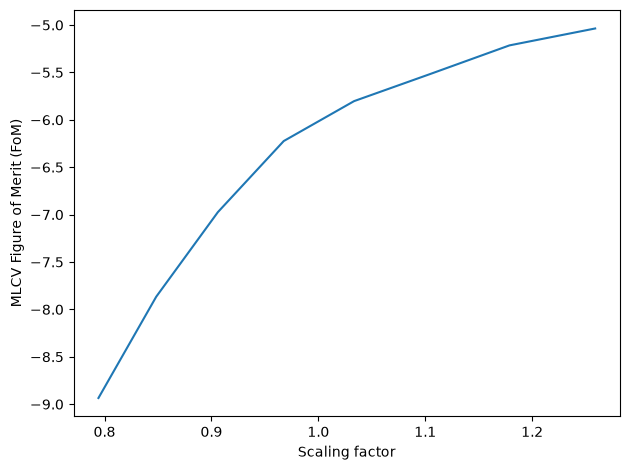

Fitting failed
attempting grid logspace start stop -0.5 0.5
Using 1000 particles for fit.
Calculating bw ... 


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=-1)]: Done   2 out of   8 | elapsed:    0.6s remaining:    1.7s
[Parallel(n_jobs=-1)]: Done   3 out of   8 | elapsed:    0.6s remaining:    0.9s
[Parallel(n_jobs=-1)]: Done   4 out of   8 | elapsed:    0.6s remaining:    0.6s
[Parallel(n_jobs=-1)]: Done   5 out of   8 | elapsed:    0.8s remaining:    0.5s
[Parallel(n_jobs=-1)]: Done   6 out of   8 | elapsed:    0.9s remaining:    0.3s
[Parallel(n_jobs=-1)]: Done   8 out of   8 | elapsed:    1.0s finished


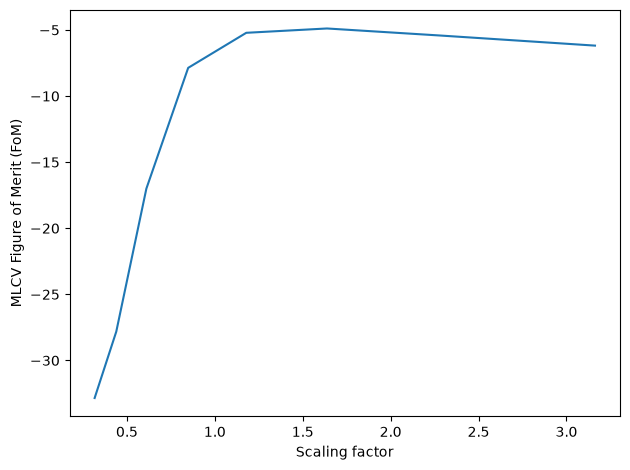

Done
Optimal bw (mlcv) = [[9.34191645e-25 8.07577637e-02 8.01640952e-02 1.55567171e-01
  1.55567171e-01 1.55567171e-01]]
Elapsed: 8 s
Successfully saved parameters file /home/jhonal/Brightify/calculated_models/file_5_mlcv_epa_21580959_1000_8s.xml
Using existing file ./examples/uniform/output.mcpl.gz
sum_weights = 21580959.0
p2 = 21580959.0
N = 21580959
N_eff = 21580959.0
attempting grid logspace start stop -0.1 0.1
Using 5000 particles for fit.
Calculating bw ... 


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=-1)]: Done   2 out of   8 | elapsed:    4.0s remaining:   11.9s
[Parallel(n_jobs=-1)]: Done   3 out of   8 | elapsed:    4.0s remaining:    6.7s
[Parallel(n_jobs=-1)]: Done   4 out of   8 | elapsed:    4.1s remaining:    4.1s
[Parallel(n_jobs=-1)]: Done   5 out of   8 | elapsed:    4.7s remaining:    2.8s
[Parallel(n_jobs=-1)]: Done   6 out of   8 | elapsed:    4.7s remaining:    1.6s
[Parallel(n_jobs=-1)]: Done   8 out of   8 | elapsed:    4.8s finished


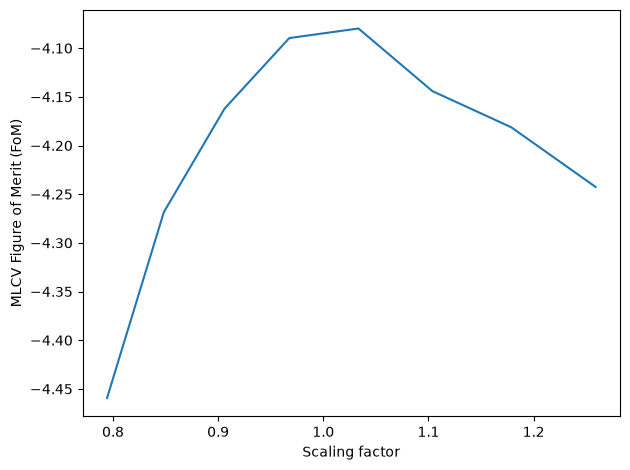

Done
Optimal bw (mlcv) = [[2.94717540e-25 5.18813308e-02 5.23170453e-02 9.85507094e-02
  9.85507094e-02 9.85507094e-02]]
Elapsed: 4 s
Successfully saved parameters file /home/jhonal/Brightify/calculated_models/file_5_mlcv_epa_21580959_5000_4s.xml
Using existing file ./examples/uniform/output.mcpl.gz
sum_weights = 21580959.0
p2 = 21580959.0
N = 21580959
N_eff = 21580959.0
attempting grid logspace start stop -0.1 0.1
Using 10000 particles for fit.
Calculating bw ... 


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=-1)]: Done   2 out of   8 | elapsed:    7.9s remaining:   23.6s
[Parallel(n_jobs=-1)]: Done   3 out of   8 | elapsed:    8.2s remaining:   13.6s
[Parallel(n_jobs=-1)]: Done   4 out of   8 | elapsed:    8.6s remaining:    8.6s
[Parallel(n_jobs=-1)]: Done   5 out of   8 | elapsed:    9.3s remaining:    5.6s
[Parallel(n_jobs=-1)]: Done   6 out of   8 | elapsed:    9.5s remaining:    3.2s
[Parallel(n_jobs=-1)]: Done   8 out of   8 | elapsed:    9.9s finished


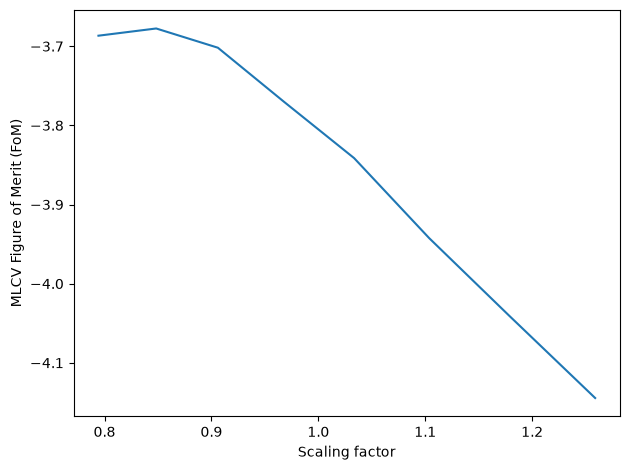

Done
Optimal bw (mlcv) = [[2.41931099e-25 4.21087906e-02 4.29551144e-02 8.11314365e-02
  8.11314365e-02 8.11314365e-02]]
Elapsed: 9 s
Successfully saved parameters file /home/jhonal/Brightify/calculated_models/file_5_mlcv_epa_21580959_10000_9s.xml
Using existing file ./examples/uniform/output.mcpl.gz
sum_weights = 21580959.0
p2 = 21580959.0
N = 21580959
N_eff = 21580959.0
attempting grid logspace start stop -0.1 0.1
Using 20000 particles for fit.
Calculating bw ... 


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=-1)]: Done   2 out of   8 | elapsed:   16.8s remaining:   50.4s
[Parallel(n_jobs=-1)]: Done   3 out of   8 | elapsed:   17.4s remaining:   29.0s
[Parallel(n_jobs=-1)]: Done   4 out of   8 | elapsed:   19.1s remaining:   19.1s
[Parallel(n_jobs=-1)]: Done   5 out of   8 | elapsed:   20.1s remaining:   12.1s
[Parallel(n_jobs=-1)]: Done   6 out of   8 | elapsed:   20.8s remaining:    6.9s
[Parallel(n_jobs=-1)]: Done   8 out of   8 | elapsed:   21.1s finished


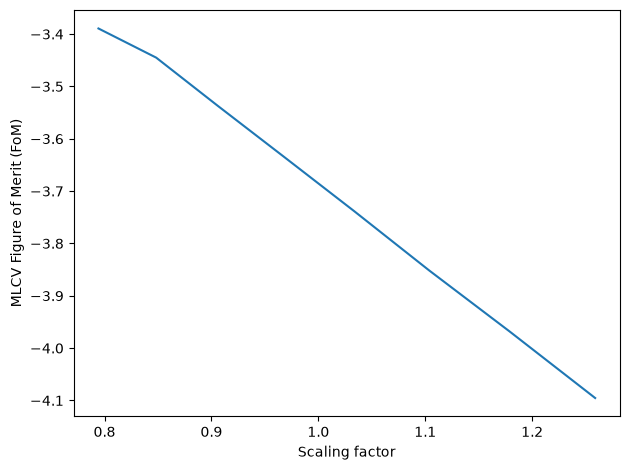

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 8 concurrent workers.


Fitting failed
attempting grid logspace start stop -0.5 0.5
Using 20000 particles for fit.
Calculating bw ... 


[Parallel(n_jobs=-1)]: Done   2 out of   8 | elapsed:   10.2s remaining:   30.5s
[Parallel(n_jobs=-1)]: Done   3 out of   8 | elapsed:   12.2s remaining:   20.4s
[Parallel(n_jobs=-1)]: Done   4 out of   8 | elapsed:   13.7s remaining:   13.7s
[Parallel(n_jobs=-1)]: Done   5 out of   8 | elapsed:   17.2s remaining:   10.3s
[Parallel(n_jobs=-1)]: Done   6 out of   8 | elapsed:   22.4s remaining:    7.5s
[Parallel(n_jobs=-1)]: Done   8 out of   8 | elapsed:   43.8s finished


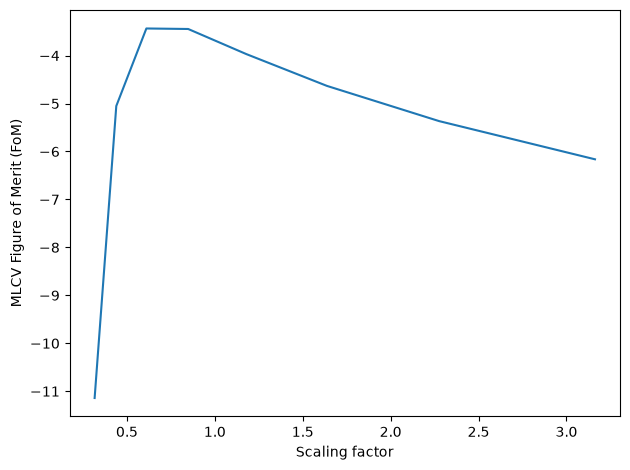

Done
Optimal bw (mlcv) = [[1.74114346e-25 3.05280784e-02 3.10845214e-02 5.82891693e-02
  5.82891693e-02 5.82891693e-02]]
Elapsed: 65 s
Successfully saved parameters file /home/jhonal/Brightify/calculated_models/file_5_mlcv_epa_21580959_20000_65s.xml
Using existing file ./examples/uniform/output.mcpl.gz
sum_weights = 21580959.0
p2 = 21580959.0
N = 21580959
N_eff = 21580959.0
attempting grid logspace start stop -0.1 0.1
Using 50000 particles for fit.
Calculating bw ... 


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=-1)]: Done   2 out of   8 | elapsed:   40.9s remaining:  2.0min
[Parallel(n_jobs=-1)]: Done   3 out of   8 | elapsed:   45.8s remaining:  1.3min
[Parallel(n_jobs=-1)]: Done   4 out of   8 | elapsed:   48.3s remaining:   48.3s
[Parallel(n_jobs=-1)]: Done   5 out of   8 | elapsed:   51.0s remaining:   30.6s
[Parallel(n_jobs=-1)]: Done   6 out of   8 | elapsed:   54.3s remaining:   18.1s
[Parallel(n_jobs=-1)]: Done   8 out of   8 | elapsed:   57.1s finished


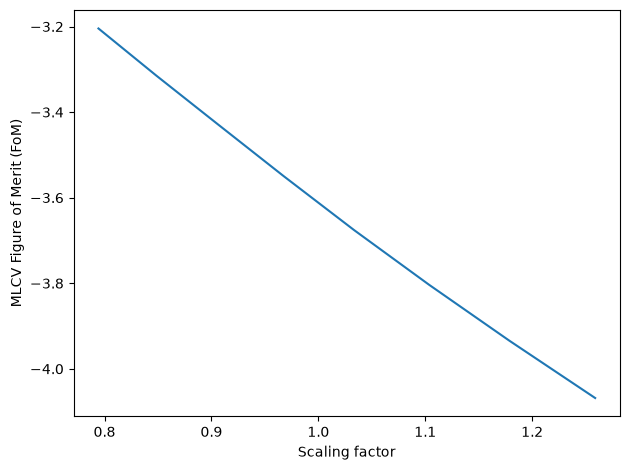

Fitting failed
attempting grid logspace start stop -0.5 0.5
Using 50000 particles for fit.
Calculating bw ... 


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=-1)]: Done   2 out of   8 | elapsed:   31.6s remaining:  1.6min
[Parallel(n_jobs=-1)]: Done   3 out of   8 | elapsed:   34.8s remaining:   58.0s
[Parallel(n_jobs=-1)]: Done   4 out of   8 | elapsed:   43.8s remaining:   43.8s
[Parallel(n_jobs=-1)]: Done   5 out of   8 | elapsed:  1.0min remaining:   37.1s
[Parallel(n_jobs=-1)]: Done   6 out of   8 | elapsed:  1.6min remaining:   31.7s
[Parallel(n_jobs=-1)]: Done   8 out of   8 | elapsed:  4.5min finished


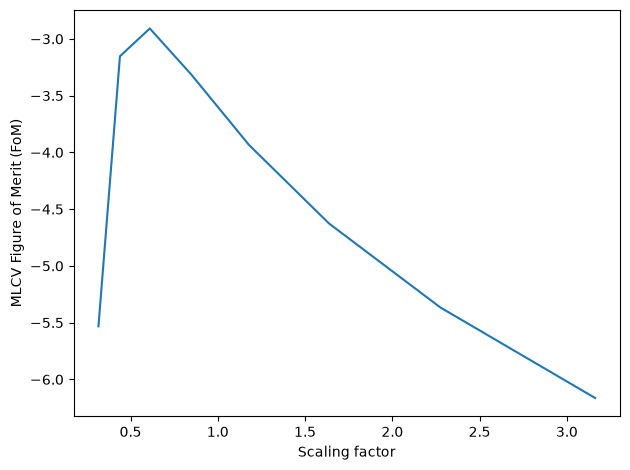

Done
Optimal bw (mlcv) = [[1.74114346e-25 3.05637124e-02 3.07739228e-02 5.82588116e-02
  5.82588116e-02 5.82588116e-02]]
Elapsed: 327 s
Successfully saved parameters file /home/jhonal/Brightify/calculated_models/file_5_mlcv_epa_21580959_50000_327s.xml
Using existing file ./examples/uniform/output.mcpl.gz
sum_weights = 21580959.0
p2 = 21580959.0
N = 21580959
N_eff = 21580959.0
attempting grid logspace start stop -0.5 0.5
Using 100000 particles for fit.
Calculating bw ... 


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=-1)]: Done   2 out of   8 | elapsed:  1.2min remaining:  3.6min
[Parallel(n_jobs=-1)]: Done   3 out of   8 | elapsed:  1.8min remaining:  2.9min
[Parallel(n_jobs=-1)]: Done   4 out of   8 | elapsed:  2.0min remaining:  2.0min


In [ ]:
import math
import time
from pathlib import Path
import numpy as np

models_folder = Path(models_folder).absolute()
if not models_folder.exists():
    Path.mkdir(models_folder)

# calculate seed bw using Silverman and a lot of data first
bw_seeds = {}

for run in ("seed_run", "main_run"):
    for i, (fn, bw_kernel_num, n_fit) in enumerate(calculate_these):

        if run == "seed_run" and fn in bw_seeds.keys():
            continue

        plist = kds.PList(
            filename=example_paths[fn],
            readformat="mcpl",
            pt=pt[fn] if fn in pt.keys() else "n",
            trasl=trasl[fn] if fn in trasl.keys() else None,
            rot=rot[fn] if fn in rot.keys() else None,
            switch_x2z=switch_x2z[fn] if fn in switch_x2z.keys() else False,
            set_params=True)

        N = plist.N

        if run == "seed_run":
            bw, kernel = "silv", "gaussian"
            n_fit = N
        else:
            bw, kernel = bw_kernel_combinations[bw_kernel_num]
            if n_fit == -1: n_fit = N
            elif 0 < n_fit < 1: n_fit = math.floor(N * n_fit)
            else: n_fit = max(min(N, n_fit), 0)
            if n_fit == 0:
                print("n_fit became zero, calculation will be skipped now.")
                continue

        source = kds.KDSource(
                plist=plist,
                geom=geometries[fn],
                bw=bw,
                kernel=kernel)
        
        fit_success = False
        start = time.perf_counter()
        mlcv_grid_multiplier = 5
        mlcv_grid_start = (-0.1 if n_fit < 100_000 else -0.5) if n_fit < 500_000 else -2.5
        mlcv_grid_stop = (0.1 if n_fit < 100_000 else 0.5) if n_fit < 500_000 else 2.5
        mlcv_grid_num = 8
        mlcv_attempt = 1
        while fit_success == False and mlcv_attempt <= 3:
            try:
                if bw=="mlcv" and fn in bw_seeds.keys():
                    seed = bw_seeds[fn]
                    grid = np.logspace(mlcv_grid_start, mlcv_grid_stop, mlcv_grid_num)
                    print("attempting grid logspace start stop", str(mlcv_grid_start), str(mlcv_grid_stop))
                    source.fit(N=n_fit, seed=seed, grid=grid)
                else:
                    source.fit(N=n_fit)
            except:
                print("Fitting failed")
                if bw=="mlcv":
                    mlcv_grid_start *= mlcv_grid_multiplier
                    mlcv_grid_stop *= mlcv_grid_multiplier
            else:
                fit_success = True
            finally:
                if bw=="mlcv":
                    mlcv_attempt += 1
                else:
                    break
                
        
        end = time.perf_counter()
        elapsed_seconds = int(end-start)
        print(f"Elapsed: {elapsed_seconds} s")

        if fit_success:
            if run=="seed_run":
                bw_seeds[fn] = source.kde.bw
            else:
                xmlfilename = str(models_folder)+"/file_"+str(fn)+"_"+bw+"_"+kernel+"_"+str(N)+"_"+str(n_fit)+"_"+str(elapsed_seconds)+"s.xml"
                source.save(xmlfilename=xmlfilename)
    if run == "seed_run":
        print("bw seeds:", bw_seeds)


### generate data from the models

In [ ]:
max_gen_N = 2_000_000 # maximum number of particles allowed to be generated per model
gen_data_folder = "./generated_data"

In [ ]:
from pathlib import Path

gen_data_folder = Path(gen_data_folder).absolute()
if not gen_data_folder.exists():
    Path.mkdir(gen_data_folder)

for model_path in models_folder.glob("*"):
    # print(model_path)
    stem = model_path.stem
    f, fn, bw, kernel, N, n_fit, elapsed = stem.split(sep="_")
    # print(f, fn, bw, kernel, N, n_fit, elapsed)
    fn = int(fn)
    N = int(N)
    n_fit = int(n_fit)
    dest_path = gen_data_folder / Path(stem).with_suffix(".mcpl.gz")
    # print(dest_path)
    resample_df(source=model_path, dest=dest_path, nout=min(N, max_gen_N), rng=123456789, force=True, no_df=True, del_dest=False, del_source=False)

### read data and produce metrics

In [ ]:
max_read_N = 2_000_000 # max. number of particles to be read per file

In [ ]:
original_data_metrics = {}

originals_used = set()
for gen_data_path in gen_data_folder.glob("*"):
    stem = gen_data_path.stem
    f, fn, bw, kernel, N, n_fit, elapsed = stem.split(sep="_")
    originals_used.add(int(fn))
for fn in originals_used:
    original_path = example_paths[fn]
    data = read_data(original_path, n=max_read_N)
    summary = data.describe().loc[['mean', 'std', 'min', 'max']]
    original_data_metrics[fn] = summary

for gen_data_path in gen_data_folder.glob("*"):
    stem = gen_data_path.stem
    f, fn, bw, kernel, N, n_fit, elapsed = stem.split(sep="_")
    fn = int(fn)
    N = int(N)
    n_fit = int(n_fit)

    gen_data = read_data(gen_data_path, n=max_read_N)

    original_path = example_paths[fn]
    original_data = read_data(original_path, n=max_read_N)
